In [30]:
!pip -q install earthengine-api geemap

In [31]:
import ee
import geemap

ee.Authenticate()

In [32]:
import ee

ee.Authenticate()
ee.Initialize(project="able-pottery-463117-r0")

print("Earth Engine initialized!")

Earth Engine initialized!


In [33]:
point = ee.Geometry.Point([80.6480, 16.5062])
roi = point.buffer(5000).bounds()

Map = geemap.Map(basemap="Esri.WorldImagery")
Map.centerObject(roi, 11)

print("Study area created!")

Study area created!


In [34]:
START_DATE = "2026-01-01"
END_DATE = "2026-10-07"

collection = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
)

image_count = collection.size().getInfo()
print("Sentinel-2 images found:", image_count)

if image_count == 0:
    raise ValueError(
        "No images found. Try a different date range or location."
    )

image = collection.sort("CLOUDY_PIXEL_PERCENTAGE").first()

image_date = ee.Date(
    image.get("system:time_start")
).format("YYYY-MM-dd").getInfo()

print("Selected image date:", image_date)

Sentinel-2 images found: 15
Selected image date: 2026-03-05


In [35]:
nir = image.select("B8").divide(10000)
red = image.select("B4").divide(10000)
blue = image.select("B2").divide(10000)

ndvi = image.normalizedDifference(
    ["B8", "B4"]
).rename("NDVI")

evi = image.expression(
    "2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))",
    {
        "NIR": nir,
        "RED": red,
        "BLUE": blue
    }
).rename("EVI")

indices = image.addBands([ndvi, evi])

print("NDVI and EVI calculated!")

NDVI and EVI calculated!


In [36]:
stats = indices.select(["NDVI", "EVI"]).reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=roi,
    scale=10,
    maxPixels=1e8
)

stats_result = stats.getInfo()

print("Mean vegetation indices:")
print(stats_result)

Mean vegetation indices:
{'EVI': 0.19726986403365554, 'NDVI': 0.2788231289531897}


In [37]:
Map.addLayer(
    image,
    {
        "bands": ["B4", "B3", "B2"],
        "min": 0,
        "max": 3000
    },
    "Sentinel-2 RGB"
)

Map.addLayer(
    ndvi,
    {
        "min": -1,
        "max": 1,
        "palette": ["brown", "yellow", "green"]
    },
    "NDVI"
)

Map.addLayer(
    evi,
    {
        "min": -1,
        "max": 1,
        "palette": ["brown", "yellow", "green"]
    },
    "EVI"
)

Map.addLayer(
    roi,
    {"color": "red"},
    "Study area boundary"
)

Map

Map(center=[16.506206877709086, 80.648075109326], controls=(WidgetControl(options=['position', 'transparent_bg…

In [38]:
import ee
import geemap
import matplotlib.pyplot as plt
import pandas as pd


In [39]:
import ee
import pandas as pd
import matplotlib.pyplot as plt

def calculate_monthly_ndvi(month):
    month = ee.Number(month)

    start = ee.Date.fromYMD(2025, month, 1)
    end = start.advance(1, "month")

    monthly_collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(roi)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
    )

    def calculate():
        composite = monthly_collection.median()

        monthly_ndvi = composite.normalizedDifference(
            ["B8", "B4"]
        ).rename("NDVI")

        result = monthly_ndvi.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=roi,
            scale=10,
            maxPixels=1e8
        )

        return ee.Feature(None, {
            "month": start.format("YYYY-MM"),
            "NDVI": result.get("NDVI"),
            "image_count": monthly_collection.size()
        })

    feature = ee.Algorithms.If(
        monthly_collection.size().gt(0),
        calculate(),
        ee.Feature(None, {
            "month": start.format("YYYY-MM"),
            "NDVI": None,
            "image_count": 0
        })
    )

    return ee.Feature(feature)


monthly_features = ee.FeatureCollection(
    ee.List.sequence(1, 12).map(calculate_monthly_ndvi)
)

monthly_data = pd.DataFrame([
    feature["properties"]
    for feature in monthly_features.getInfo()["features"]
])

monthly_data["NDVI"] = pd.to_numeric(
    monthly_data["NDVI"], errors="coerce"
)

print(monthly_data)

        NDVI  image_count    month
0   0.307421            2  2025-01
1   0.291417            5  2025-02
2   0.284301            2  2025-03
3   0.254180            4  2025-04
4   0.272699            1  2025-05
5   0.323358            1  2025-06
6        NaN            0  2025-07
7        NaN            0  2025-08
8   0.316192            1  2025-09
9   0.267119            1  2025-10
10  0.357620            4  2025-11
11  0.283268            6  2025-12


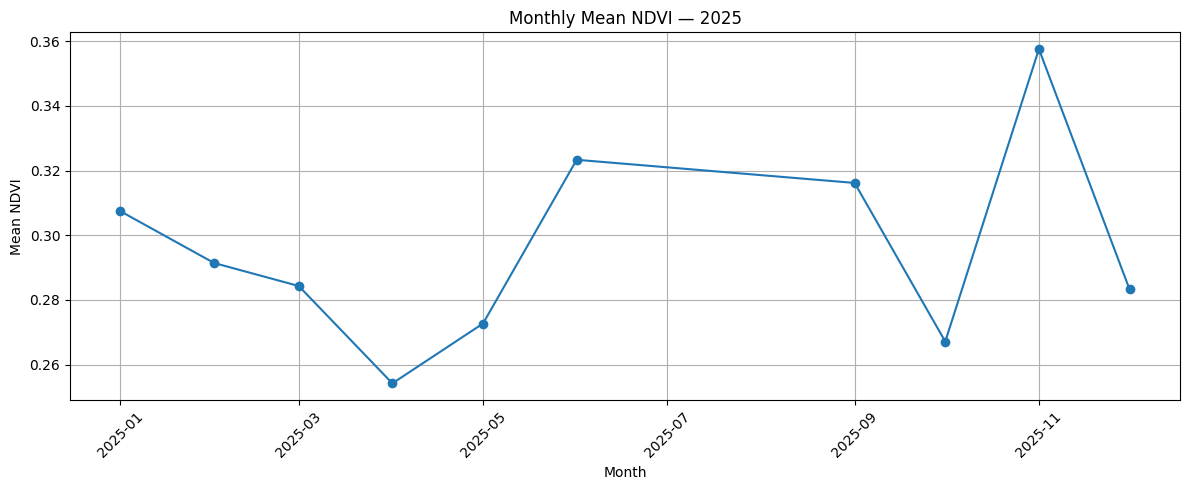

In [40]:
monthly_data["month"] = pd.to_datetime(monthly_data["month"])

valid_data = monthly_data.dropna(subset=["NDVI"])

plt.figure(figsize=(12, 5))
plt.plot(valid_data["month"], valid_data["NDVI"], marker="o")
plt.title("Monthly Mean NDVI — 2025")
plt.xlabel("Month")
plt.ylabel("Mean NDVI")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()